In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

In [2]:
main_df = pd.read_excel(r"D:\My Learning\RFM Analysis\RFM_Raw_Data.xlsx")

In [3]:
main_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    2000 non-null   str           
 1   Date              2000 non-null   datetime64[us]
 2   Product ID        2000 non-null   str           
 3   Product Name      2000 non-null   str           
 4   Product Category  2000 non-null   str           
 5   Quantity          2000 non-null   int64         
 6   PPU               2000 non-null   int64         
 7   Amount            2000 non-null   int64         
 8   Customer ID       2000 non-null   str           
 9   Region            2000 non-null   str           
dtypes: datetime64[us](1), int64(3), str(6)
memory usage: 156.4 KB


In [4]:
main_df.shape

(2000, 10)

In [5]:
df = main_df.copy()

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    2000 non-null   str           
 1   Date              2000 non-null   datetime64[us]
 2   Product ID        2000 non-null   str           
 3   Product Name      2000 non-null   str           
 4   Product Category  2000 non-null   str           
 5   Quantity          2000 non-null   int64         
 6   PPU               2000 non-null   int64         
 7   Amount            2000 non-null   int64         
 8   Customer ID       2000 non-null   str           
 9   Region            2000 non-null   str           
dtypes: datetime64[us](1), int64(3), str(6)
memory usage: 156.4 KB


In [7]:
df.drop(columns = ['Transaction ID','Product ID'] , inplace = True)

Removing unnessary columns

Depend on situation to rduce the space

In [8]:
df.head()

,Date,Product Name,Product Category,Quantity,PPU,Amount,Customer ID,Region
0,2025-01-01,A4 Printer Paper (500 Sheets),Office Supplies,13,25000,325000,Customer-190,Yangon
1,2025-01-01,A4 Printer Paper (500 Sheets),Office Supplies,500,25000,12500000,Customer-985,Bago
2,2025-01-01,Adjustable Monitor Arm,Furniture,25,180000,4500000,Customer-625,Mandalay
3,2025-01-01,Wireless Mechanical Keyboard,Electronics,41,350000,14350000,Customer-882,Yangon
4,2025-01-01,Adjustable Monitor Arm,Furniture,28,180000,5040000,Customer-801,Bago


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              2000 non-null   datetime64[us]
 1   Product Name      2000 non-null   str           
 2   Product Category  2000 non-null   str           
 3   Quantity          2000 non-null   int64         
 4   PPU               2000 non-null   int64         
 5   Amount            2000 non-null   int64         
 6   Customer ID       2000 non-null   str           
 7   Region            2000 non-null   str           
dtypes: datetime64[us](1), int64(3), str(4)
memory usage: 125.1 KB


In [10]:
print(f'Total Unique Customer is: {df['Customer ID'].nunique()}')

Total Unique Customer is: 812


In [11]:
total_unique_customers = df['Customer ID'].nunique()

total_unique_customers

812

At first, we can find total amount spending by customers.

In [12]:
Monetary = df.groupby('Customer ID').agg(Total_amount = ('Amount' , 'sum')).reset_index()

In [13]:
Frequency = df.groupby('Customer ID').agg(Total_Frequency = ('Customer ID', 'count')).reset_index()

To Find Recency, we need to define analysis date. 



In [14]:
import datetime as dt

In [15]:
df['Date'].min()

Timestamp('2025-01-01 00:00:00')

In [16]:
df['Date'].max()

Timestamp('2025-12-31 00:00:00')

In [17]:
dataset_duration= (df['Date'].max() - df['Date'].min()).days + 1

dataset_duration

365

In [18]:
last_purchase = df.groupby('Customer ID').agg(last_date = ('Date','max')).reset_index()

In [19]:
last_purchase

,Customer ID,last_date
0,Customer-002,2025-12-25
1,Customer-004,2025-11-04
2,Customer-005,2025-09-22
3,Customer-006,2025-03-06
4,Customer-007,2025-06-26
...,...,...
807,Customer-995,2025-12-23
808,Customer-996,2025-09-18
809,Customer-997,2025-09-18
810,Customer-998,2025-10-13


We must define analysis date.

This depend on your business.

In [20]:
analysis_date = df['Date'].max() + dt.timedelta(days= 1)

In [21]:
analysis_date

Timestamp('2026-01-01 00:00:00')

In [22]:
last_purchase['Recency'] = analysis_date - last_purchase['last_date']

In [23]:
last_purchase.drop(columns='last_date',inplace= True)

In [24]:
Recency = last_purchase.copy()

In [25]:
Recency

,Customer ID,Recency
0,Customer-002,7 days
1,Customer-004,58 days
2,Customer-005,101 days
3,Customer-006,301 days
4,Customer-007,189 days
...,...,...
807,Customer-995,9 days
808,Customer-996,105 days
809,Customer-997,105 days
810,Customer-998,80 days


We finally done each table need caculation of RFM. 

So, we need to merge this three table as a fact table.

In [26]:
fact_table = Monetary.merge(Recency , how = 
               'inner' , on = 'Customer ID').merge(Frequency,
                                                   how = 'inner' , on = 'Customer ID')

In [27]:
fact_table

,Customer ID,Total_amount,Recency,Total_Frequency
0,Customer-002,17425000,7 days,3
1,Customer-004,69590000,58 days,5
2,Customer-005,22950000,101 days,2
3,Customer-006,39900000,301 days,1
4,Customer-007,250000,189 days,1
...,...,...,...,...
807,Customer-995,6900000,9 days,2
808,Customer-996,14870000,105 days,3
809,Customer-997,58470000,105 days,3
810,Customer-998,852750000,80 days,5


In [28]:
fact_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 812 entries, 0 to 811
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Customer ID      812 non-null    str            
 1   Total_amount     812 non-null    int64          
 2   Recency          812 non-null    timedelta64[us]
 3   Total_Frequency  812 non-null    int64          
dtypes: int64(2), str(1), timedelta64[us](1)
memory usage: 25.5 KB


We need to give score to each RFM.

In this bacis leve, we use the median value to separate the Low and Hight for each category.

In [29]:
median_monetary = fact_table['Total_amount'].median()

median_recency = fact_table['Recency'].median()

median_frequency = fact_table['Total_Frequency'].median()


In [30]:
def monetary_score(x):
    if x > median_monetary:
        return 'High'
    else:
        return 'Low'

In [31]:
def recency_score(x):
    if x < median_recency:
        return 'High'
    else:
        return 'Low'

In [32]:
def frequency_score(x):
    if x > median_frequency:
        return 'High'
    else:
        return 'Low'

In [33]:
fact_table['Monetary_score'] = fact_table['Total_amount'].apply(monetary_score)

In [34]:
fact_table['Recency_score'] = fact_table['Recency'].apply(recency_score)

In [35]:
fact_table['Total_Frequency'] = fact_table['Total_Frequency'].apply(frequency_score)

In [36]:
fact_table

,Customer ID,Total_amount,Recency,Total_Frequency,Monetary_score,Recency_score
0,Customer-002,17425000,7 days,High,Low,High
1,Customer-004,69590000,58 days,High,High,High
2,Customer-005,22950000,101 days,Low,High,Low
3,Customer-006,39900000,301 days,Low,High,Low
4,Customer-007,250000,189 days,Low,Low,Low
...,...,...,...,...,...,...
807,Customer-995,6900000,9 days,Low,Low,High
808,Customer-996,14870000,105 days,High,Low,Low
809,Customer-997,58470000,105 days,High,High,Low
810,Customer-998,852750000,80 days,High,High,High


Using RFM Score to segment the customers.

From RFM score to Actional Insight for marketing team or someone.

HHH	🥇 Champions

HHL	💎 Loyal High Value

HLH	🛒 Big Spenders (Occasional)

HLL	🌱 Potential Loyalists

LHH	⚠️ At Risk High Value

LHL	🔁 Former Loyal Low Spend

LLH	💸 Lost High Spenders

LLL	💤 Lost / Low Value


In [37]:


def segmentation(row):

    # Champions
    if row['Recency_score'] == 'High' and row['Total_Frequency'] == 'High' and row['Monetary_score'] == 'High':
        return 'Champions'

    # Loyal High Value
    elif row['Recency_score'] == 'High' and row['Total_Frequency'] == 'High' and row['Monetary_score'] == 'Low':
        return 'Loyal High Value'

    # Big Spenders (Occasional)
    elif row['Recency_score'] == 'High' and row['Total_Frequency'] == 'Low' and row['Monetary_score'] == 'High':
        return 'Big Spenders (Occasional)'

    # Potential Loyalists
    elif row['Recency_score'] == 'High' and row['Total_Frequency'] == 'Low' and row['Monetary_score'] == 'Low':
        return 'Potential Loyalists'

    # At Risk High Value
    elif row['Recency_score'] == 'Low' and row['Total_Frequency'] == 'High' and row['Monetary_score'] == 'High':
        return 'At Risk High Value'

    # Former Loyal Low Spend
    elif row['Recency_score'] == 'Low' and row['Total_Frequency'] == 'High' and row['Monetary_score'] == 'Low':
        return 'Former Loyal Low Spend'

    # Lost High Spenders
    elif row['Recency_score'] == 'Low' and row['Total_Frequency'] == 'Low' and row['Monetary_score'] == 'High':
        return 'Lost High Spenders'

    # Lost / Low Value
    elif row['Recency_score'] == 'Low' and row['Total_Frequency'] == 'Low' and row['Monetary_score'] == 'Low':
        return 'Lost / Low Value'

    else:
        return 'Unclassified'



In [38]:
fact_table['Customer_segment'] = fact_table.apply(segmentation ,axis= 1)

In [39]:
fact_table['Customer_segment'].value_counts()

Customer_segment
Lost / Low Value             229
Champions                    183
Potential Loyalists          122
Lost High Spenders            86
At Risk High Value            75
Big Spenders (Occasional)     62
Loyal High Value              36
Former Loyal Low Spend        19
Name: count, dtype: int64

### RFM Analysis in Advance Form 



In [40]:
df.head()

,Date,Product Name,Product Category,Quantity,PPU,Amount,Customer ID,Region
0,2025-01-01,A4 Printer Paper (500 Sheets),Office Supplies,13,25000,325000,Customer-190,Yangon
1,2025-01-01,A4 Printer Paper (500 Sheets),Office Supplies,500,25000,12500000,Customer-985,Bago
2,2025-01-01,Adjustable Monitor Arm,Furniture,25,180000,4500000,Customer-625,Mandalay
3,2025-01-01,Wireless Mechanical Keyboard,Electronics,41,350000,14350000,Customer-882,Yangon
4,2025-01-01,Adjustable Monitor Arm,Furniture,28,180000,5040000,Customer-801,Bago


In [41]:
filter_df = df.loc[:,['Date' , 'Amount' , 'Customer ID']]

In [42]:
filter_df = filter_df.reindex(columns=['Customer ID' , 'Date' , 'Amount'])

In [43]:
filter_df

,Customer ID,Date,Amount
0,Customer-190,2025-01-01,325000
1,Customer-985,2025-01-01,12500000
2,Customer-625,2025-01-01,4500000
3,Customer-882,2025-01-01,14350000
4,Customer-801,2025-01-01,5040000
...,...,...,...
1995,Customer-305,2025-12-31,4680000
1996,Customer-619,2025-12-31,9500000
1997,Customer-349,2025-12-31,5250000
1998,Customer-360,2025-12-31,150000


In [44]:
filter_df.sort_values(['Customer ID' , 'Date'] , ascending= True , inplace= True)

In [45]:
filter_df.head()

,Customer ID,Date,Amount
641,Customer-002,2025-04-24,925000
1874,Customer-002,2025-12-09,11250000
1960,Customer-002,2025-12-25,5250000
704,Customer-004,2025-05-05,15000000
904,Customer-004,2025-06-17,5850000


In [46]:
filter_df['Next_date'] = filter_df.groupby('Customer ID')['Date'].shift(-1)

In [47]:
filter_df.head()

,Customer ID,Date,Amount,Next_date
641,Customer-002,2025-04-24,925000,2025-12-09
1874,Customer-002,2025-12-09,11250000,2025-12-25
1960,Customer-002,2025-12-25,5250000,NaT
704,Customer-004,2025-05-05,15000000,2025-06-17
904,Customer-004,2025-06-17,5850000,2025-09-09


In [48]:
filter_df['Date_gap'] = filter_df['Next_date'] - filter_df['Date']

In [49]:
filter_df.reset_index(inplace= True)

In [50]:
filter_df.drop(columns = 'index' , inplace = True)

In [51]:
filter_df

,Customer ID,Date,Amount,Next_date,Date_gap
0,Customer-002,2025-04-24,925000,2025-12-09,229 days
1,Customer-002,2025-12-09,11250000,2025-12-25,16 days
2,Customer-002,2025-12-25,5250000,NaT,NaT
3,Customer-004,2025-05-05,15000000,2025-06-17,43 days
4,Customer-004,2025-06-17,5850000,2025-09-09,84 days
...,...,...,...,...,...
1995,Customer-998,2025-08-07,313500000,2025-09-05,29 days
1996,Customer-998,2025-09-05,35000000,2025-10-13,38 days
1997,Customer-998,2025-10-13,1250000,NaT,NaT
1998,Customer-999,2025-01-01,6300000,2025-07-17,197 days


In this situation, we must define Return date to define the customer is return or not return.

Defining return date depends on your situations. 

In [52]:
def return_define(x):
    days = x.days   # converts Timedelta to integer days
    if days > 30:
        return 0
    elif days <= 30:
        return 1
    else:
        return days   # or return 0/1 or NaN — your choice

In [53]:
filter_df['Return'] = filter_df['Date_gap'].apply(return_define)

In [54]:
filter_df.head()

,Customer ID,Date,Amount,Next_date,Date_gap,Return
0,Customer-002,2025-04-24,925000,2025-12-09,229 days,0.0
1,Customer-002,2025-12-09,11250000,2025-12-25,16 days,1.0
2,Customer-002,2025-12-25,5250000,NaT,NaT,NaN
3,Customer-004,2025-05-05,15000000,2025-06-17,43 days,0.0
4,Customer-004,2025-06-17,5850000,2025-09-09,84 days,0.0


In [55]:
filter_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype          
---  ------       --------------  -----          
 0   Customer ID  2000 non-null   str            
 1   Date         2000 non-null   datetime64[us] 
 2   Amount       2000 non-null   int64          
 3   Next_date    1188 non-null   datetime64[us] 
 4   Date_gap     1188 non-null   timedelta64[us]
 5   Return       1188 non-null   float64        
dtypes: datetime64[us](2), float64(1), int64(1), str(1), timedelta64[us](1)
memory usage: 93.9 KB


In [56]:
filter_df.head(20)

,Customer ID,Date,Amount,Next_date,Date_gap,Return
0,Customer-002,2025-04-24,925000,2025-12-09,229 days,0.0
1,Customer-002,2025-12-09,11250000,2025-12-25,16 days,1.0
2,Customer-002,2025-12-25,5250000,NaT,NaT,NaN
3,Customer-004,2025-05-05,15000000,2025-06-17,43 days,0.0
4,Customer-004,2025-06-17,5850000,2025-09-09,84 days,0.0
5,Customer-004,2025-09-09,2520000,2025-09-23,14 days,1.0
6,Customer-004,2025-09-23,43700000,2025-11-04,42 days,0.0
7,Customer-004,2025-11-04,2520000,NaT,NaT,NaN
8,Customer-005,2025-07-10,16150000,2025-09-22,74 days,0.0
9,Customer-005,2025-09-22,6800000,NaT,NaT,NaN


In [57]:
Return_or_not = filter_df.groupby('Customer ID').agg(Return_or_not = ('Return' , 'sum'))

In [58]:
def return_or_not(x):
    if x >= 1:
        return 1
    else:
        return 0

In [59]:
Return_or_not['True_False'] = Return_or_not['Return_or_not'].apply(return_or_not)

In [60]:
last_purchase.head()

,Customer ID,Recency
0,Customer-002,7 days
1,Customer-004,58 days
2,Customer-005,101 days
3,Customer-006,301 days
4,Customer-007,189 days


In [61]:
Return_or_not.reset_index(inplace= True)

In [62]:
Return_or_not = Return_or_not.merge(last_purchase, how = 'inner' , on = 'Customer ID')

In [63]:
Return_or_not.drop(columns = 'Return_or_not' , inplace = True)

In [64]:
last_date = df.groupby('Customer ID').agg(last_date = ('Date' , 'max')).reset_index()

In [65]:
Recency_table = Return_or_not.merge(last_date, how = 'inner' , on = 'Customer ID' )

In [66]:
Recency_table = Recency_table.reindex(columns= ['Customer ID' , 'last_date' , 'Recency' , 'True_False'])

In [67]:
Recency_table.head()

,Customer ID,last_date,Recency,True_False
0,Customer-002,2025-12-25,7 days,1
1,Customer-004,2025-11-04,58 days,1
2,Customer-005,2025-09-22,101 days,0
3,Customer-006,2025-03-06,301 days,0
4,Customer-007,2025-06-26,189 days,0


In [68]:
Recency_table.rename(columns={'Customer ID':'Customer ID',
                              'last_date':'last_date',
                              'Recency':'Recency',
                              'True_False':'Return'} ,inplace= True)

In [69]:
Recency_table

,Customer ID,last_date,Recency,Return
0,Customer-002,2025-12-25,7 days,1
1,Customer-004,2025-11-04,58 days,1
2,Customer-005,2025-09-22,101 days,0
3,Customer-006,2025-03-06,301 days,0
4,Customer-007,2025-06-26,189 days,0
...,...,...,...,...
807,Customer-995,2025-12-23,9 days,1
808,Customer-996,2025-09-18,105 days,1
809,Customer-997,2025-09-18,105 days,0
810,Customer-998,2025-10-13,80 days,1


In [70]:
Recency_table['Recency'].min()

Timedelta('1 days 00:00:00')

In [71]:
Recency_table['Recency'].max()

Timedelta('365 days 00:00:00')

The minimun return day is 1.

The maximun return day is 365. 

We need to do a busket. 

In [72]:
def recency_busket(x):
    day = x.days
    if day <= 30:
        return '0-30'
    elif day <= 60:
        return '31-60'
    elif day <= 90:
        return '61-90'
    else:
        return '90+'

In [73]:
Recency_table['Busktet'] = Recency_table['Recency'].apply(recency_busket)

In [74]:
Recency_table.head()

,Customer ID,last_date,Recency,Return,Busktet
0,Customer-002,2025-12-25,7 days,1,0-30
1,Customer-004,2025-11-04,58 days,1,31-60
2,Customer-005,2025-09-22,101 days,0,90+
3,Customer-006,2025-03-06,301 days,0,90+
4,Customer-007,2025-06-26,189 days,0,90+


In [75]:
Recency_summary = Recency_table.groupby('Busktet').agg(total_customers = ('Busktet', 'count'),
                                    return_customers = ('Return' , 'sum'))

In [76]:
Recency_summary['Return_rate'] = round(Recency_summary['return_customers'] / Recency_summary['total_customers'] , 4) * 100

In [77]:
Recency_summary['Gap'] = Recency_summary['Return_rate'].diff()

In [78]:
Recency_summary

,total_customers,return_customers,Return_rate,Gap
Busktet,,,,
0-30,153,61,39.87,NaN
31-60,127,51,40.16,0.29
61-90,109,30,27.52,-12.64
90+,423,86,20.33,-7.19


So, 60 days is our maximum day to return.

To Find Repeat Rate

In [79]:
Frequency

,Customer ID,Total_Frequency
0,Customer-002,3
1,Customer-004,5
2,Customer-005,2
3,Customer-006,1
4,Customer-007,1
...,...,...
807,Customer-995,2
808,Customer-996,3
809,Customer-997,3
810,Customer-998,5


In [80]:
repeat_rate = Frequency.groupby('Total_Frequency').agg(total_count = ('Total_Frequency' , 'count')).reset_index()

In [81]:
repeat_rate

,Total_Frequency,total_count
0,1,292
1,2,207
2,3,150
3,4,78
4,5,29
5,6,26
6,7,18
7,8,5
8,9,5
9,10,2


In [82]:
count = Frequency['Total_Frequency'].value_counts().sort_index()

In [83]:
desc_count = count.sort_index(ascending= False).cumsum().sort_index()

In [84]:
desc_count_df = desc_count.reset_index('Total_Frequency')

In [85]:
desc_count_df

,Total_Frequency,count
0,1,812
1,2,520
2,3,313
3,4,163
4,5,85
5,6,56
6,7,30
7,8,12
8,9,7
9,10,2


In [86]:
repeat_rate_final = repeat_rate.merge(desc_count_df , on = 'Total_Frequency' , how = 'inner')

In [87]:
repeat_rate_final.rename(columns={'Total_Frequency':'Frequency_type',
                          'total_count':'Frequency_count',
                          'count':'repeat_count'} ,inplace= True)

In [88]:
repeat_rate_final['repeat_rate'] = round(repeat_rate_final['repeat_count'] / len(Frequency),4) * 100

In [89]:
repeat_rate_final

,Frequency_type,Frequency_count,repeat_count,repeat_rate
0,1,292,812,100.00
1,2,207,520,64.04
2,3,150,313,38.55
3,4,78,163,20.07
4,5,29,85,10.47
5,6,26,56,6.90
6,7,18,30,3.69
7,8,5,12,1.48
8,9,5,7,0.86
9,10,2,2,0.25


In [90]:
repeat_rate_final['Gap_rate'] = repeat_rate_final['repeat_rate'].diff()

In [91]:
repeat_rate_final

,Frequency_type,Frequency_count,repeat_count,repeat_rate,Gap_rate
0,1,292,812,100.00,NaN
1,2,207,520,64.04,-35.96
2,3,150,313,38.55,-25.49
3,4,78,163,20.07,-18.48
4,5,29,85,10.47,-9.60
5,6,26,56,6.90,-3.57
6,7,18,30,3.69,-3.21
7,8,5,12,1.48,-2.21
8,9,5,7,0.86,-0.62
9,10,2,2,0.25,-0.61


In [92]:
repeat_rate_final['Change_of_change'] = repeat_rate_final['Gap_rate'].diff()

In [93]:
repeat_rate_final

,Frequency_type,Frequency_count,repeat_count,repeat_rate,Gap_rate,Change_of_change
0,1,292,812,100.00,NaN,NaN
1,2,207,520,64.04,-35.96,NaN
2,3,150,313,38.55,-25.49,10.47
3,4,78,163,20.07,-18.48,7.01
4,5,29,85,10.47,-9.60,8.88
5,6,26,56,6.90,-3.57,6.03
6,7,18,30,3.69,-3.21,0.36
7,8,5,12,1.48,-2.21,1.00
8,9,5,7,0.86,-0.62,1.59
9,10,2,2,0.25,-0.61,0.01


In [94]:
repeat_rate_final.drop(columns='Frequency_count' , inplace= True)

In [95]:
repeat_rate_final

,Frequency_type,repeat_count,repeat_rate,Gap_rate,Change_of_change
0,1,812,100.00,NaN,NaN
1,2,520,64.04,-35.96,NaN
2,3,313,38.55,-25.49,10.47
3,4,163,20.07,-18.48,7.01
4,5,85,10.47,-9.60,8.88
5,6,56,6.90,-3.57,6.03
6,7,30,3.69,-3.21,0.36
7,8,12,1.48,-2.21,1.00
8,9,7,0.86,-0.62,1.59
9,10,2,0.25,-0.61,0.01


# Customer Repeat Frequency Analysis

## 1. Overview

This report analyses **repeat purchase frequency** for a customer base of **812 customers**. It shows how many customers return for a 2nd, 3rd, 4th… up to 10th purchase, along with the **repeat rate** (percentage of the original 812 still active at each frequency), the **gap rate** (change from previous frequency), and the **change of change** (acceleration/deceleration of the drop).

**Key conclusion:** The meaningful repeat frequency ends at **frequency 3**. Beyond frequency 3, the repeat rate falls below 40% and the remaining customer base becomes a small long tail.

---

## 2. Data Table

| Frequency Type | Repeat Count | Repeat Rate (%) | Gap Rate (pp) | Change of Change (pp) |
|----------------|--------------|-----------------|---------------|------------------------|
| 1              | 812          | 100.00          | –             | –                      |
| 2              | 520          | 64.04           | −35.96        | –                      |
| 3              | 313          | 38.55           | −25.49        | +10.47                 |
| 4              | 163          | 20.07           | −18.48        | +7.01                  |
| 5              | 85           | 10.47           | −9.60         | +8.88                  |
| 6              | 56           | 6.90            | −3.57         | +6.03                  |
| 7              | 30           | 3.69            | −3.21         | +0.36                  |
| 8              | 12           | 1.48            | −2.21         | +1.00                  |
| 9              | 7            | 0.86            | −0.62         | +1.59                  |
| 10             | 2            | 0.25            | −0.61         | +0.01                  |

---

## 3. Column Explanations

| Column | Meaning |
|--------|---------|
| **Frequency Type** | Number of purchases made (1 = bought once, 2 = bought twice, etc.) |
| **Repeat Count** | How many customers made at least that many purchases |
| **Repeat Rate** | Percentage of the original 812 customers still active at that frequency |
| **Gap Rate** | Change in repeat rate from the previous frequency (percentage points) |
| **Change of Change** | How the gap rate itself is changing (acceleration or deceleration of the drop) |

---

## 4. Key Findings

### 4.1 The Core Drop-off

- **F1 → F2:** Repeat rate drops from 100% to 64.04% (**−35.96 pp**).
  Nearly **36% of customers never return** after their first purchase. This is the single largest drop.

- **F2 → F3:** Repeat rate drops from 64.04% to 38.55% (**−25.49 pp**).
  Another **quarter of the base** is lost. By now, **only 313 of 812 customers (38.55%)** are still active.

- **F3 → F4:** Repeat rate drops from 38.55% to 20.07% (**−18.48 pp**).
  The drop slows but is still substantial — by F4, **fewer than 1 in 5 customers remain**.

### 4.2 Why Frequency 3 Is the Cutoff

By **frequency 3**, the repeat rate has already fallen from 100% to **38.55%** — a cumulative loss of **61.45 percentage points**. Three reasons justify treating frequency 3 as the maximum meaningful tier:

1. **Rate falls below 40%:** At F3, the repeat rate is under 40%. This is a natural psychological and statistical break point.
2. **Absolute volume shrinks sharply:**
   - F1 = 812
   - F2 = 520
   - F3 = 313
   - F4 = 163 (only **20% of the original base**)
3. **Marginal drops become smaller in percentage points:**
   F1→F2 (−35.96) → F2→F3 (−25.49) → F3→F4 (−18.48). After F3, the "gap" is no longer dramatic in absolute percentage points, but the customer base is already very small.

> **Conclusion:** Customers who reach frequency 3 are the **core loyal segment**. Beyond frequency 3, the remaining customers are a small long tail of highly engaged buyers.

### 4.3 The Long Tail Beyond Frequency 3

From frequency 4 onwards, the numbers become very small:

| Frequency | Customers | % of Original Base |
|-----------|-----------|---------------------|
| 4         | 163       | 20.07%              |
| 5         | 85        | 10.47%              |
| 6         | 56        | 6.90%               |
| 7         | 30        | 3.69%               |
| 8         | 12        | 1.48%               |
| 9         | 7         | 0.86%               |
| 10        | 2         | 0.25%               |

- Only **2 customers** reach frequency 10.
- This long tail is valuable for **loyalty programs** but not for **mass marketing**. Any campaign targeting frequencies 5+ would reach very few customers.

### 4.4 The "Change of Change" Signal

The **Change of Change** column (positive values from F3 onward) shows that the **rate of drop is decelerating**. The sharpest decline is F1→F2; after that, each drop is smaller than the previous one in percentage points. This confirms that the bulk of the loss happens **early** (between F1 and F3), which is why frequency 3 is the natural cutoff.

---

## 5. Business Interpretation

| Finding | Business Meaning |
|---------|------------------|
| ~36% never return after first purchase | Onboarding and first-to-second purchase experience is the biggest retention lever. |
| By F3, 61.45% of customers are lost | The "first 3 purchases" are the **critical window** for building a repeat habit. |
| After F3, volumes are tiny | Focus on converting customers **to** F3, not beyond. |
| Loyal long tail (F5–F10) exists | A small but valuable segment for VIP/loyalty programs. |

**Core insight:** The business has a **"3-purchase retention ceiling."** If a customer reaches their 3rd purchase, they are likely a genuine repeat customer. If they don't reach F3, they churn. Therefore, the **maximum meaningful frequency for mass retention strategy is frequency 3.**

---

## 6. Recommendations

1. **Focus on F1 → F2 conversion.**
   The largest drop is here (−35.96 pp). Improve onboarding, post-purchase communication, and first-repeat incentives.

2. **Target F2 → F3 conversion.**
   Another −25.49 pp is lost here. Offer a "buy 2 get 1" style offer or a loyalty milestone reward to push customers to their 3rd purchase.

3. **Treat F3 as the "loyal customer" threshold.**
   Customers at F3 or above should be segmented into a loyalty program, while customers below F3 should be targeted for reactivation.

4. **Do not over-invest in mass campaigns beyond F3.**
   Frequencies 4–10 contain only 20% of the base. Target them with **VIP or personalized offers**, not mass marketing.

5. **Monitor the "Change of Change" metric.**
   If the drop from F1→F2 starts shrinking, it means retention is improving. If it grows, the onboarding process needs attention.

---

## 7. Conclusion

- **Maximum meaningful frequency:** **3 purchases**
- **Repeat rate at frequency 3:** **38.55%**
- **Cumulative loss by frequency 3:** **61.45% of customers**
- **Beyond frequency 3:** Long tail, small volumes, high loyalty
- **Biggest retention lever:** Converting first-time buyers into second- and third-time buyers

The data confirms that customer retention is a **"first-three-purchases" game.** Winning at F1→F2 and F2→F3 is the key to building a sustainable repeat customer base. Beyond F3, the business should focus on **loyalty and personalization**, not mass acquisition.

---

In [96]:
Frequency

,Customer ID,Total_Frequency
0,Customer-002,3
1,Customer-004,5
2,Customer-005,2
3,Customer-006,1
4,Customer-007,1
...,...,...
807,Customer-995,2
808,Customer-996,3
809,Customer-997,3
810,Customer-998,5


In [97]:
def frequency_rate(x):
    if x >= 3:
        return 'H'
    else:
        return 'L'

In [98]:
Frequency['Frequency_rate'] = Frequency['Total_Frequency'].apply(frequency_rate)

In [99]:
Frequency

,Customer ID,Total_Frequency,Frequency_rate
0,Customer-002,3,H
1,Customer-004,5,H
2,Customer-005,2,L
3,Customer-006,1,L
4,Customer-007,1,L
...,...,...,...
807,Customer-995,2,L
808,Customer-996,3,H
809,Customer-997,3,H
810,Customer-998,5,H


In [100]:
Frequency__Table_adv = Frequency.copy()

In [101]:
Frequency__Table_adv

,Customer ID,Total_Frequency,Frequency_rate
0,Customer-002,3,H
1,Customer-004,5,H
2,Customer-005,2,L
3,Customer-006,1,L
4,Customer-007,1,L
...,...,...,...
807,Customer-995,2,L
808,Customer-996,3,H
809,Customer-997,3,H
810,Customer-998,5,H


In [102]:
Monetary

,Customer ID,Total_amount
0,Customer-002,17425000
1,Customer-004,69590000
2,Customer-005,22950000
3,Customer-006,39900000
4,Customer-007,250000
...,...,...
807,Customer-995,6900000
808,Customer-996,14870000
809,Customer-997,58470000
810,Customer-998,852750000


In [103]:
Monetary['Percent_total'] = round(Monetary['Total_amount'] / Monetary['Total_amount'].sum() , 4) * 100

In [104]:
Monetary.sort_values('Total_amount' , ascending= False , inplace= True)

In [105]:
Monetary.loc[Monetary['Percent_total'] >= 80 , :]

,Customer ID,Total_amount,Percent_total


In [106]:
Monetary['Cumulative_total'] = Monetary['Percent_total'].cumsum()

In [107]:
Monetary

,Customer ID,Total_amount,Percent_total,Cumulative_total
587,Customer-732,1516250000,2.53,2.53
496,Customer-620,1357000000,2.27,4.80
160,Customer-193,1332050000,2.23,7.03
395,Customer-499,1265250000,2.11,9.14
202,Customer-251,1214250000,2.03,11.17
...,...,...,...,...
721,Customer-893,425000,0.00,99.95
301,Customer-377,400000,0.00,99.95
51,Customer-067,300000,0.00,99.95
253,Customer-311,275000,0.00,99.95


In [108]:
Monetary.loc[Monetary['Cumulative_total'] <= 80.1 , :].min()

Customer ID         Customer-004
Total_amount            49090000
Percent_total               0.08
Cumulative_total            2.53
dtype: object

In [109]:
standard_Monetary_amount = Monetary[Monetary['Cumulative_total'] <= 80.1]['Total_amount'].min()

In [110]:
Monetary.head()

,Customer ID,Total_amount,Percent_total,Cumulative_total
587,Customer-732,1516250000,2.53,2.53
496,Customer-620,1357000000,2.27,4.80
160,Customer-193,1332050000,2.23,7.03
395,Customer-499,1265250000,2.11,9.14
202,Customer-251,1214250000,2.03,11.17


In [111]:
def amount_class(x):
    if x <= 80.1:
        return 'H'
    else:
        return 'L'

In [112]:
Monetary['Monetary_Class'] = Monetary['Cumulative_total'].apply(amount_class)

In [113]:
Monetary

,Customer ID,Total_amount,Percent_total,Cumulative_total,Monetary_Class
587,Customer-732,1516250000,2.53,2.53,H
496,Customer-620,1357000000,2.27,4.80,H
160,Customer-193,1332050000,2.23,7.03,H
395,Customer-499,1265250000,2.11,9.14,H
202,Customer-251,1214250000,2.03,11.17,H
...,...,...,...,...,...
721,Customer-893,425000,0.00,99.95,L
301,Customer-377,400000,0.00,99.95,L
51,Customer-067,300000,0.00,99.95,L
253,Customer-311,275000,0.00,99.95,L


In [114]:
Monetary_table_adv = Monetary.loc[:,['Customer ID' , 'Total_amount' , 'Monetary_Class']]  

In [115]:
Frequency__Table_adv

,Customer ID,Total_Frequency,Frequency_rate
0,Customer-002,3,H
1,Customer-004,5,H
2,Customer-005,2,L
3,Customer-006,1,L
4,Customer-007,1,L
...,...,...,...
807,Customer-995,2,L
808,Customer-996,3,H
809,Customer-997,3,H
810,Customer-998,5,H


In [116]:
Recency

,Customer ID,Recency
0,Customer-002,7 days
1,Customer-004,58 days
2,Customer-005,101 days
3,Customer-006,301 days
4,Customer-007,189 days
...,...,...
807,Customer-995,9 days
808,Customer-996,105 days
809,Customer-997,105 days
810,Customer-998,80 days


In [117]:
Recency_adv = Recency.copy()

In [118]:
def adv_recency_score(x):
    if x <= 60:
        return 'H'
    else:
        return 'L'

In [119]:
Recency_adv.info()

<class 'pandas.DataFrame'>
RangeIndex: 812 entries, 0 to 811
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype          
---  ------       --------------  -----          
 0   Customer ID  812 non-null    str            
 1   Recency      812 non-null    timedelta64[us]
dtypes: str(1), timedelta64[us](1)
memory usage: 12.8 KB


In [120]:
Recency_adv['Recency'] = Recency_adv['Recency'].dt.days

In [121]:
Recency_adv.info()

<class 'pandas.DataFrame'>
RangeIndex: 812 entries, 0 to 811
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Customer ID  812 non-null    str  
 1   Recency      812 non-null    int64
dtypes: int64(1), str(1)
memory usage: 12.8 KB


In [122]:
Recency_adv['R_score'] = Recency_adv['Recency'].apply(adv_recency_score)

In [123]:
Recency_adv

,Customer ID,Recency,R_score
0,Customer-002,7,H
1,Customer-004,58,H
2,Customer-005,101,L
3,Customer-006,301,L
4,Customer-007,189,L
...,...,...,...
807,Customer-995,9,H
808,Customer-996,105,L
809,Customer-997,105,L
810,Customer-998,80,L


In [124]:
Frequency__Table_adv

,Customer ID,Total_Frequency,Frequency_rate
0,Customer-002,3,H
1,Customer-004,5,H
2,Customer-005,2,L
3,Customer-006,1,L
4,Customer-007,1,L
...,...,...,...
807,Customer-995,2,L
808,Customer-996,3,H
809,Customer-997,3,H
810,Customer-998,5,H


In [125]:
Recency_adv

,Customer ID,Recency,R_score
0,Customer-002,7,H
1,Customer-004,58,H
2,Customer-005,101,L
3,Customer-006,301,L
4,Customer-007,189,L
...,...,...,...
807,Customer-995,9,H
808,Customer-996,105,L
809,Customer-997,105,L
810,Customer-998,80,L


In [126]:
Monetary_table_adv

,Customer ID,Total_amount,Monetary_Class
587,Customer-732,1516250000,H
496,Customer-620,1357000000,H
160,Customer-193,1332050000,H
395,Customer-499,1265250000,H
202,Customer-251,1214250000,H
...,...,...,...
721,Customer-893,425000,L
301,Customer-377,400000,L
51,Customer-067,300000,L
253,Customer-311,275000,L


In [127]:
RFM_advance = Frequency__Table_adv.merge(Recency_adv , on = 'Customer ID' , how = 'inner').merge(Monetary_table_adv, on = 'Customer ID',
                                                                                   how = 'inner')

In [128]:
RFM_advance

,Customer ID,Total_Frequency,Frequency_rate,Recency,R_score,Total_amount,Monetary_Class
0,Customer-002,3,H,7,H,17425000,L
1,Customer-004,5,H,58,H,69590000,H
2,Customer-005,2,L,101,L,22950000,L
3,Customer-006,1,L,301,L,39900000,L
4,Customer-007,1,L,189,L,250000,L
...,...,...,...,...,...,...,...
807,Customer-995,2,L,9,H,6900000,L
808,Customer-996,3,H,105,L,14870000,L
809,Customer-997,3,H,105,L,58470000,H
810,Customer-998,5,H,80,L,852750000,H


In [129]:
RFM_advance = RFM_advance.reindex(columns=['Customer ID' , 'Total_Frequency' , 
                             'Total_amount','Recency','R_score', 'Frequency_rate','Monetary_Class'])

In [130]:
RFM_advance.rename(columns={'Frequency_rate':'F_score',
                            'Monetary_Class':'M_socre'},inplace= True)

In [131]:
RFM_advance

,Customer ID,Total_Frequency,Total_amount,Recency,R_score,F_score,M_socre
0,Customer-002,3,17425000,7,H,H,L
1,Customer-004,5,69590000,58,H,H,H
2,Customer-005,2,22950000,101,L,L,L
3,Customer-006,1,39900000,301,L,L,L
4,Customer-007,1,250000,189,L,L,L
...,...,...,...,...,...,...,...
807,Customer-995,2,6900000,9,H,L,L
808,Customer-996,3,14870000,105,L,H,L
809,Customer-997,3,58470000,105,L,H,H
810,Customer-998,5,852750000,80,L,H,H


In [132]:
RFM_advance.rename(columns={'M_socre':'M_score'},inplace= True)

In [133]:
def RFM_segmentation(row):

    # Champions
    if row['R_score'] == 'H' and row['F_score'] == 'H' and row['M_score'] == 'H':
        return 'Champions'

    # Loyal H Value
    elif row['R_score'] == 'H' and row['F_score'] == 'H' and row['M_score'] == 'L':
        return 'Loyal H Value'

    # Big Spenders (Occasional)
    elif row['R_score'] == 'H' and row['F_score'] == 'L' and row['M_score'] == 'H':
        return 'Big Spenders (Occasional)'

    # Potential Loyalists
    elif row['R_score'] == 'H' and row['F_score'] == 'L' and row['M_score'] == 'L':
        return 'Potential Loyalists'

    # At Risk H Value
    elif row['R_score'] == 'L' and row['F_score'] == 'H' and row['M_score'] == 'H':
        return 'At Risk H Value'

    # Former Loyal L Spend
    elif row['R_score'] == 'L' and row['F_score'] == 'H' and row['M_score'] == 'L':
        return 'Former Loyal L Spend'

    # Lost H Spenders
    elif row['R_score'] == 'L' and row['F_score'] == 'L' and row['M_score'] == 'H':
        return 'Lost H Spenders'

    # Lost / L Value
    elif row['R_score'] == 'L' and row['F_score'] == 'L' and row['M_score'] == 'L':
        return 'Lost / L Value'

    else:
        return 'Unclassified'



In [134]:
RFM_advance['Segmentation'] = RFM_advance.apply(RFM_segmentation , axis= 1)

In [135]:
RFM_advance.sort_values('Total_amount' , ascending= False)

,Customer ID,Total_Frequency,Total_amount,Recency,R_score,F_score,M_score,Segmentation
587,Customer-732,6,1516250000,35,H,H,H,Champions
496,Customer-620,6,1357000000,55,H,H,H,Champions
160,Customer-193,6,1332050000,6,H,H,H,Champions
395,Customer-499,9,1265250000,113,L,H,H,At Risk H Value
202,Customer-251,6,1214250000,71,L,H,H,At Risk H Value
...,...,...,...,...,...,...,...,...
721,Customer-893,1,425000,174,L,L,L,Lost / L Value
301,Customer-377,1,400000,13,H,L,L,Potential Loyalists
51,Customer-067,1,300000,105,L,L,L,Lost / L Value
253,Customer-311,1,275000,192,L,L,L,Lost / L Value


Text(0.5, 1.0, 'Bacis RFM Customer Segmentation Technique')

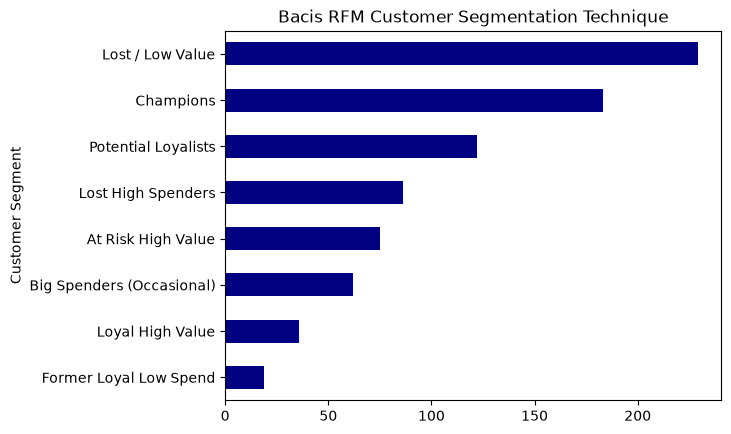

In [136]:
fact_table['Customer_segment'].value_counts().plot(kind = 'barh' , color = 'navy')
ax = plt.gca()
ax.invert_yaxis()
plt.ylabel('Customer Segment')
plt.title('Bacis RFM Customer Segmentation Technique')

Text(0.5, 1.0, 'Advance RFM Customer Segmentaion')

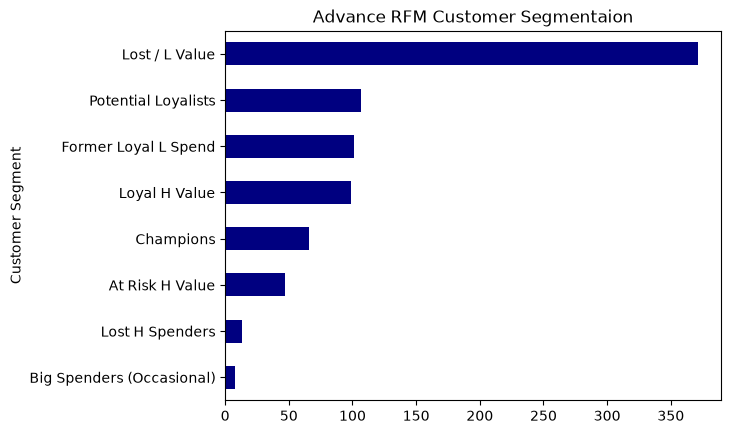

In [137]:
RFM_advance['Segmentation'].value_counts().plot(kind = 'barh' , color = 'navy')
ax = plt.gca()
ax.invert_yaxis()
plt.ylabel('Customer Segment')
plt.title('Advance RFM Customer Segmentaion')

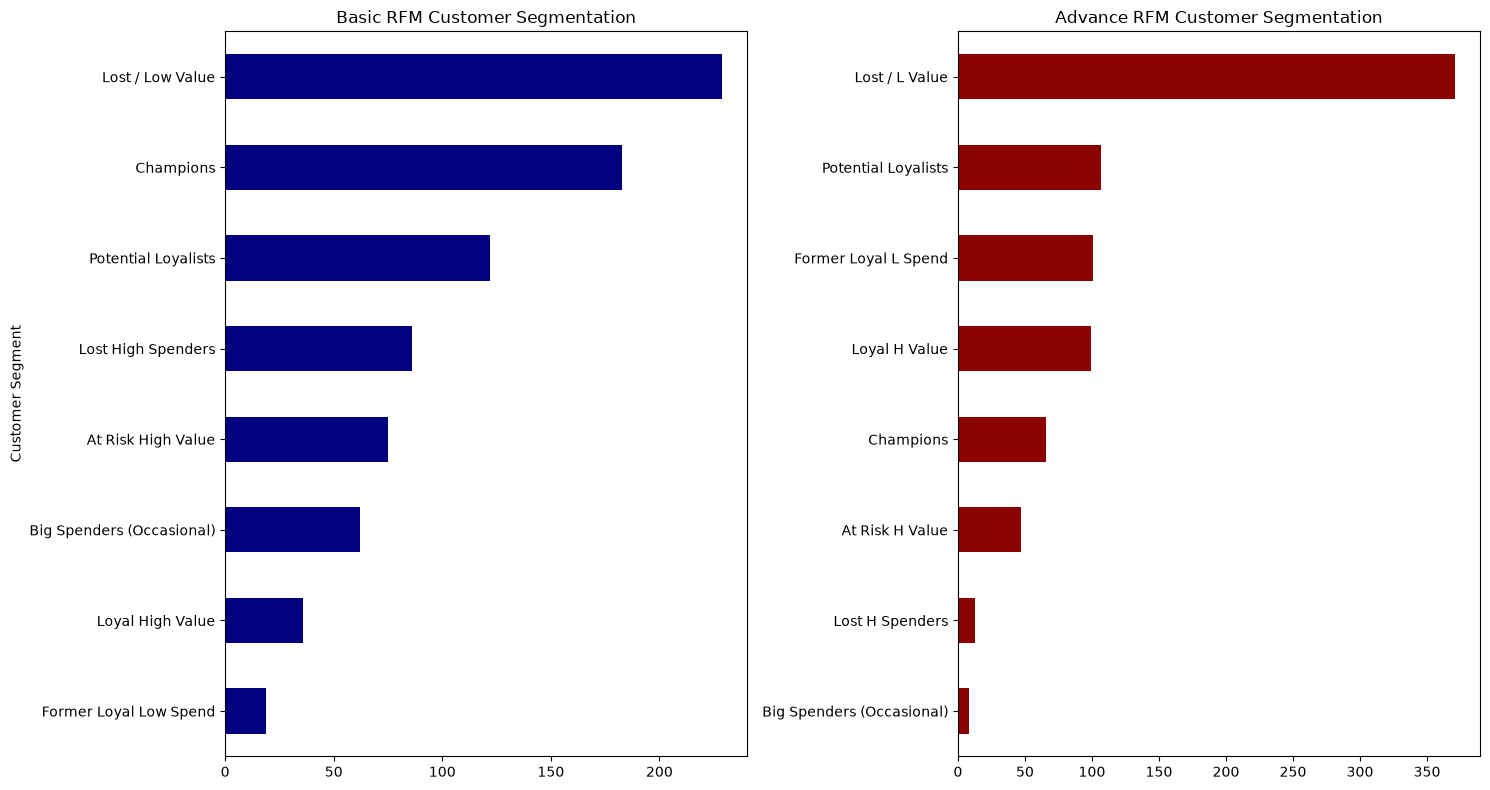

In [138]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))
fact_table['Customer_segment'].value_counts().plot(kind='barh', color='navy', ax=ax1)

ax1.invert_yaxis()
ax1.set_title('Basic RFM Customer Segmentation')
ax1.set_ylabel('Customer Segment')

RFM_advance['Segmentation'].value_counts().plot(kind='barh', color='darkred', ax=ax2)
ax2.invert_yaxis()
ax2.set_title('Advance RFM Customer Segmentation')
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

In [139]:
RFM_advance_summary = RFM_advance.groupby('Segmentation').agg(Total_revenue = ('Total_amount' , 'sum'),
                                        Number_customers = ('Customer ID' , 'count')).sort_values('Total_revenue' , ascending= False)

In [140]:
RFM_advance_summary.reset_index(inplace= True)

In [141]:
RFM_advance_summary

,Segmentation,Total_revenue,Number_customers
0,Champions,31807055000,66
1,At Risk H Value,14921080000,47
2,Lost / L Value,4954610000,371
3,Former Loyal L Spend,2765895000,101
4,Loyal H Value,2565690000,99
5,Potential Loyalists,1666380000,107
6,Lost H Spenders,733000000,13
7,Big Spenders (Occasional),437890000,8


In [142]:
from matplotlib.ticker import FuncFormatter

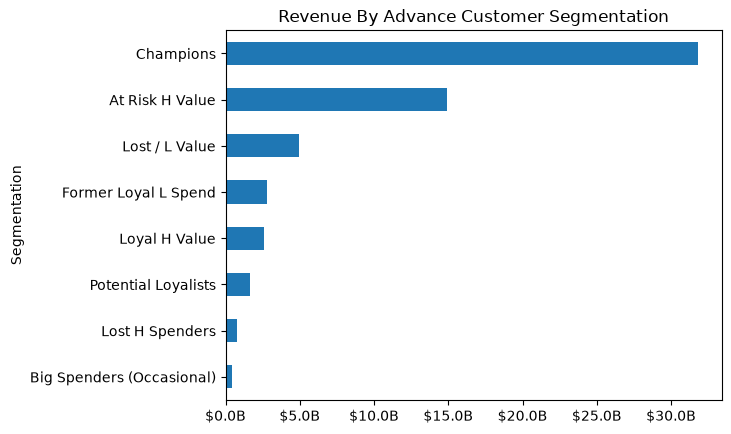

In [143]:
RFM_advance_summary.plot(y = 'Total_revenue' , x = 'Segmentation' , kind= 'barh')
ax = plt.gca()
ax.invert_yaxis()
ax.set_title('Revenue By Advance Customer Segmentation')
ax.legend().remove()
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x/1e9:,.1f}B'))

In [144]:
RFM_basic = fact_table.copy()

In [145]:
RFM_advance.to_excel(r'D:\My Learning\RFM Analysis\'RFM_advance.xlsx')

In [146]:
RFM_basic.to_excel(r"D:\My Learning\RFM Analysis\'RFM_basic.xlsx")